### ⚙️ Load GROMACS and Dependencies

> **Note:**  
> These scripts are designed for **ACCRE**.  
> If you are using a different HPC, adjust the module load commands to match your system setup.

#### 🧩 Option 1 – Adjust for Your HPC
Edit the `module load` lines below to match the versions of **GROMACS**, **OpenMPI**, **CUDA**, or other dependencies available on your cluster.

#### 🧪 Option 2 – Use a Manual GROMACS Path
If your cluster does **not** use module environments, remove the `module load` commands and instead source your GROMACS installation manually:
```bash
source /path/to/gromacs/bin/GMXRC


In [7]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [8]:
load_gmx_plumed()

### 📦 Import Core Libraries

These libraries cover numerical operations, plotting, system utilities, and data handling.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import subprocess
import os
from contextlib import contextmanager
import re
import pandas
import pathlib

In [10]:
%cd /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish

/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish


/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/Compiler/gcccore/ipykernel/2025a/lib/python3.12/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


## 🧠 PCA (Cα) Analysis for SMOG Simulations - Run SLURM script !

SLURM batch script to perform **Cα-based PCA** across all systems and temperatures using GROMACS + PLUMED.

- 🔬 Systems: **3PRG**, **6ONJ**, **6ONI**
- 🌡️ Processes all temperature replicas
- 📐 Computes covariance, eigenvalues/vectors, and PC1–PC2 projections
- 🗺️ Generates 2D free-energy surfaces (Gibbs landscapes)
- 🧩 Extracts extreme structures along PC1 and PC2

All PCA outputs are organized under `Advanced_Analysis/{system}/{temperature}/PCA/`  
and are used downstream for ensemble comparison and figure generation.

The SLURM configuration targets ACCRE; please adjust modules and resources if running on a different system.

In [10]:
%%bash 

cat > Advanced_Analysis/PCA_Calpha_SMOG.slurm << EOF
#!/bin/bash
#SBATCH --job-name=SMOG_All_PCA
#SBATCH --mail-user=
#SBATCH --mail-type=ALL
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --mem=60G
#SBATCH --time=10-00:00:00
#SBATCH --gres=gpu:nvidia_rtx_a6000:1
#SBATCH --partition=batch_gpu
#SBATCH --account=csb_gpu_acc
#SBATCH --output=SMOG_all_out_%j.log
#SBATCH --error=SMOG_all_err_%j.log

set -e
set -o pipefail

# ==============================
# MODULES + GMX + PLUMED
# ==============================
module load StdEnvACCRE/2023
module load gcc/12.3
module load openmpi/4.1.5
module load cuda/12.2

source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
export PATH=$HOME/plumed-2.9.2/bin:$PATH

# ==============================
# RUN LOCATION: Advanced_Analysis/
# ==============================
ROOTDIR=$(pwd)

systems=("3PRG" "6ONJ" "6ONI")
temps=("100" "102" "104" "106" "106.5" "107" "107.5" "108" "108.5" "109" "109.5" "110" "112" "114" "116" "118")

# ✅ xpm2txt is in Advanced_Analysis/
XPM2TXT="../xpm2txt.py"

# ==============================
# MAIN LOOP
# ==============================
for sys in "${systems[@]}"; do

    echo "▶ Entering system: $sys"
    cd "$ROOTDIR/$sys"

    for T in "${temps[@]}"; do

        # ✅ Correct absolute paths to INPUTS
        TPR="$ROOTDIR/../${sys}/${T}/t-${sys}.tpr"
        XTC="$ROOTDIR/../${sys}/${T}__trajout.xtc"

        OUTDIR="./${T}/PCA"
        mkdir -p "$OUTDIR"

        BASE="${OUTDIR}/${sys}_${T}"

        # =========================
        # ✅ SAFETY CHECKS
        # =========================
        [[ -f "$TPR" ]] || { echo "❌ Missing TPR: $TPR"; continue; }
        [[ -f "$XTC" ]] || { echo "❌ Missing XTC: $XTC"; continue; }

        echo "✅ PCA for $sys at ${T}K"

        # =========================
        # ✅ PCA COVARIANCE (Cα)
        # =========================
        echo 1 1 | gmx_mpi covar \
            -f "$XTC" \
            -s "$TPR" \
            -o "${BASE}_eigenval.xvg" \
            -v "${BASE}_eigenvect.trr" \
            -xpm "${BASE}_covar.xpm"

        # =========================
        # ✅ 2D PROJECTION PC1 vs PC2
        # =========================
        echo 1 1 | gmx_mpi anaeig \
            -v "${BASE}_eigenvect.trr" \
            -f "$XTC" \
            -s "$TPR" \
            -first 1 -last 2 \
            -proj "${BASE}_proj_eig.xvg" \
            -2d "${BASE}_2d_proj.xvg"

        # =========================
        # ✅ FREE ENERGY SURFACE
        # =========================
        gmx_mpi sham \
            -f "${BASE}_2d_proj.xvg" \
            -ls "${BASE}_gibbs.xpm" \
            -notime

        # =========================
        # ✅ XPM → TXT (FIXED PATH)
        # =========================
        python "$ROOTDIR/xpm2txt.py" \
            -f "${BASE}_gibbs.xpm" \
            -o "${BASE}_gibbs.txt"

        # =========================
        # ✅ EXTREME STRUCTURES PC1
        # =========================
        echo 1 1 | gmx_mpi anaeig \
            -v "${BASE}_eigenvect.trr" \
            -s "$TPR" \
            -f "$XTC" \
            -extr "${BASE}_PC1_extreme.pdb" \
            -first 1 -last 1 -nframes 400

        # =========================
        # ✅ EXTREME STRUCTURES PC2
        # =========================
        echo 1 1 | gmx_mpi anaeig \
            -v "${BASE}_eigenvect.trr" \
            -s "$TPR" \
            -f "$XTC" \
            -extr "${BASE}_PC2_extreme.pdb" \
            -first 2 -last 2 -nframes 400

    done

    cd "$ROOTDIR"

done

echo "✅✅✅ ALL PCA ANALYSIS FINISHED FOR 3PRG, 6ONJ, 6ONI ✅✅✅"


EOF

sbatch Advanced_Analysis/PCA_Calpha_SMOG.slurm

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

▶ TEST PCA using PER-TEMP TPR: 3PRG at 100 K
→ Using TPR: ../3PRG/100/t-3PRG.tpr
→ Using XTC: ../3PRG/100__trajout.xtc
→ Running covar...


                :-) GROMACS - gmx covar, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/Advanced_Analysis
Command line:
  gmx_mpi covar -f ../3PRG/100__trajout.xtc -s ../3PRG/100/t-3PRG.tpr -o ./3PRG/100/PCA_TEST/3PRG_100_eigenval.xvg -v ./3PRG/100/PCA_TEST/3PRG_100_eigenvect.trr -xpm ./3PRG/100/PCA_TEST/3PRG_100_covar.xpm

Reading file ../3PRG/100/t-3PRG.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file ../3PRG/100/t-3PRG.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainC

Process was interrupted.


CalledProcessError: Command 'b'set -e\n\necho "\xe2\x96\xb6 TEST PCA using PER-TEMP TPR: 3PRG at 100 K"\n\n# ==============================\n# CONFIG (SINGLE TEST CASE)\n# ==============================\nSYS="3PRG"\nT="100"\n\n# \xe2\x9c\x85 TPR is INSIDE the temperature folder (unique per temp)\nTPR="../${SYS}/${T}/t-${SYS}.tpr"\n\n# \xe2\x9c\x85 Trajectory file (lives in system root)\nXTC="../${SYS}/${T}__trajout.xtc"\n\n# \xe2\x9c\x85 Output directory\nOUTDIR="./${SYS}/${T}/PCA_TEST"\nmkdir -p "$OUTDIR"\n\nBASE="${OUTDIR}/${SYS}_${T}"\n\n# ==============================\n# \xe2\x9c\x85 SAFETY CHECKS\n# ==============================\n[[ -f "$TPR" ]] || { echo "\xe2\x9d\x8c Missing TPR: $TPR"; exit 1; }\n[[ -f "$XTC" ]] || { echo "\xe2\x9d\x8c Missing XTC: $XTC"; exit 1; }\n\necho "\xe2\x86\x92 Using TPR: $TPR"\necho "\xe2\x86\x92 Using XTC: $XTC"\n\n# =========================\n# \xe2\x9c\x85 PCA COVARIANCE (C\xce\xb1)\n# =========================\necho "\xe2\x86\x92 Running covar..

## 🧪 Sanity Check: RMSD–PCA Frame Alignment

Validation step to ensure **frame-by-frame consistency** between RMSD time series and PCA projections across **all systems and all temperatures**.

- RMSD and PCA data are loaded independently
- Metadata and header lines are ignored
- Frame counts are compared for each system–temperature pair
- Analysis proceeds only when RMSD, PC1, and PC2 lengths match exactly

Successful completion confirms that PCA landscapes can be **safely colored or correlated with RMSD** without frame misalignment.


In [5]:
import numpy as np
import os

def load_clean_xy(fname):
    X, Y = [], []
    with open(fname) as f:
        for line in f:
            if line.startswith(("#", "@")):
                continue
            parts = line.split()
            if len(parts) < 2:
                continue
            try:
                X.append(float(parts[0]))
                Y.append(float(parts[1]))
            except ValueError:
                pass
    return np.array(X), np.array(Y)

# =========================
# CONFIG
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]

temps = [
    "100","102","104","106",
    "106.5","107","107.5","108",
    "108.5","109","109.5","110",
    "112","114","116","118"
]

BASE = "Advanced_Analysis"

# =========================
# REPORT STORAGE
# =========================
report = {}

print("🔍 RMSD–PCA Frame Alignment Check (All Systems, All Temperatures)\n")

for sys in systems:
    report[sys] = {}

    for T in temps:

        rmsd_file = f"{BASE}/{sys}/{T}/RMSD_{sys}_{T}.xvg"
        proj_file = f"{BASE}/{sys}/{T}/PCA/{sys}_{T}_2d_proj.xvg"

        if not (os.path.isfile(rmsd_file) and os.path.isfile(proj_file)):
            report[sys][T] = "MISSING FILES"
            continue

        # Load RMSD
        _, RMSD = load_clean_xy(rmsd_file)

        # Load PCA
        proj = np.loadtxt(proj_file, comments=["@", "#"])
        PC1 = proj[:, 0]
        PC2 = proj[:, 1]

        if len(RMSD) == len(PC1) == len(PC2):
            report[sys][T] = "OK"
        else:
            report[sys][T] = f"MISMATCH (RMSD={len(RMSD)}, PCA={len(PC1)})"

# =========================
# FINAL SUMMARY REPORT
# =========================
print("📋 ALIGNMENT SUMMARY\n")

all_ok = True

for sys in systems:
    print(f"▶ {sys}")
    for T in temps:
        status = report[sys].get(T, "NOT CHECKED")
        icon = "✅" if status == "OK" else "❌"
        print(f"  {icon} {T} K : {status}")
        if status != "OK":
            all_ok = False
    print()

if all_ok:
    print("🎯 ALL SYSTEMS AND ALL TEMPERATURES PASSED ALIGNMENT CHECKS.")
else:
    print("⚠️ Some system/temperature combinations failed. See details above.")


🔍 RMSD–PCA Frame Alignment Check (All Systems, All Temperatures)

📋 ALIGNMENT SUMMARY

▶ 3PRG
  ✅ 100 K : OK
  ✅ 102 K : OK
  ✅ 104 K : OK
  ✅ 106 K : OK
  ✅ 106.5 K : OK
  ✅ 107 K : OK
  ✅ 107.5 K : OK
  ✅ 108 K : OK
  ✅ 108.5 K : OK
  ✅ 109 K : OK
  ✅ 109.5 K : OK
  ✅ 110 K : OK
  ✅ 112 K : OK
  ✅ 114 K : OK
  ✅ 116 K : OK
  ✅ 118 K : OK

▶ 6ONJ
  ✅ 100 K : OK
  ✅ 102 K : OK
  ✅ 104 K : OK
  ✅ 106 K : OK
  ✅ 106.5 K : OK
  ✅ 107 K : OK
  ✅ 107.5 K : OK
  ✅ 108 K : OK
  ✅ 108.5 K : OK
  ✅ 109 K : OK
  ✅ 109.5 K : OK
  ✅ 110 K : OK
  ✅ 112 K : OK
  ✅ 114 K : OK
  ✅ 116 K : OK
  ✅ 118 K : OK

▶ 6ONI
  ✅ 100 K : OK
  ✅ 102 K : OK
  ✅ 104 K : OK
  ✅ 106 K : OK
  ✅ 106.5 K : OK
  ✅ 107 K : OK
  ✅ 107.5 K : OK
  ✅ 108 K : OK
  ✅ 108.5 K : OK
  ✅ 109 K : OK
  ✅ 109.5 K : OK
  ✅ 110 K : OK
  ✅ 112 K : OK
  ✅ 114 K : OK
  ✅ 116 K : OK
  ✅ 118 K : OK

🎯 ALL SYSTEMS AND ALL TEMPERATURES PASSED ALIGNMENT CHECKS.


## 📦 PCA Data Export

PCA output files are copied from `Advanced_Analysis` to the output folder  
for generating publication-quality figures.

Files are placed directly in each temperature directory  
(no additional PCA subfolders).


In [46]:
%%bash
set -euo pipefail

# ==============================
# CONFIG
# ==============================
systems=("3PRG" "6ONJ" "6ONI")
temps=("100" "102" "104" "106" "106.5" "107" "107.5" "108" "108.5" "109" "109.5" "110" "112" "114" "116" "118")

INPUT_ROOT="Advanced_Analysis"
OUTPUT_ROOT="/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures"

# PCA files to copy (pattern-based, system-aware)
files=(
  "{sys}_{T}_2d_proj.xvg"
  "{sys}_{T}_eigenval.xvg"
  "{sys}_{T}_gibbs.xpm"
  "{sys}_{T}_gibbs.txt"
  "{sys}_{T}_proj_eig.xvg"
)

# ==============================
# COPY LOOP
# ==============================
for sys in "${systems[@]}"; do
  for T in "${temps[@]}"; do

    src_dir="${INPUT_ROOT}/${sys}/${T}/PCA"
    dst_dir="${OUTPUT_ROOT}/${sys}/${T}"

    [[ -d "$src_dir" ]] || continue
    mkdir -p "$dst_dir"

    for pattern in "${files[@]}"; do
      fname="${pattern/\{sys\}/$sys}"
      fname="${fname/\{T\}/$T}"

      src="${src_dir}/${fname}"
      dst="${dst_dir}/${fname}"

      if [[ -f "$src" ]]; then
        cp -v "$src" "$dst"
      fi
    done

  done
done

echo "🎯 PCA files copied to output folder (no PCA subdirectories)"


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

'Advanced_Analysis/3PRG/100/PCA/3PRG_100_2d_proj.xvg' -> '/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/100/3PRG_100_2d_proj.xvg'
'Advanced_Analysis/3PRG/100/PCA/3PRG_100_eigenval.xvg' -> '/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/100/3PRG_100_eigenval.xvg'
'Advanced_Analysis/3PRG/100/PCA/3PRG_100_gibbs.xpm' -> '/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/100/3PRG_100_gibbs.xpm'
'Advanced_Analysis/3PRG/100/PCA/3PRG_100_gibbs.txt' -> '/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/100/3PRG_100_gibbs.txt'
'Advanced_Analysis/3PRG/100/PCA/3PRG_100_proj_eig.xvg' -> '/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/100/3PRG_100_proj_eig.xvg'
'Advanced_Analysis/3PRG/102/PCA/3PRG_102_2d_proj.xvg' -> '/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/102/3PRG_102_2d_proj.xvg'
'Advanced_Analysis/3PRG/102/PCA/3PRG_102_eig

## 🗺️ PCA Free Energy Landscapes

PC1–PC2 free energy surfaces computed from PCA projections  
and shown side-by-side for **3PRG**, **6ONJ**, and **6ONI** at 102 K.

All panels use a common PC axis range for direct comparison.


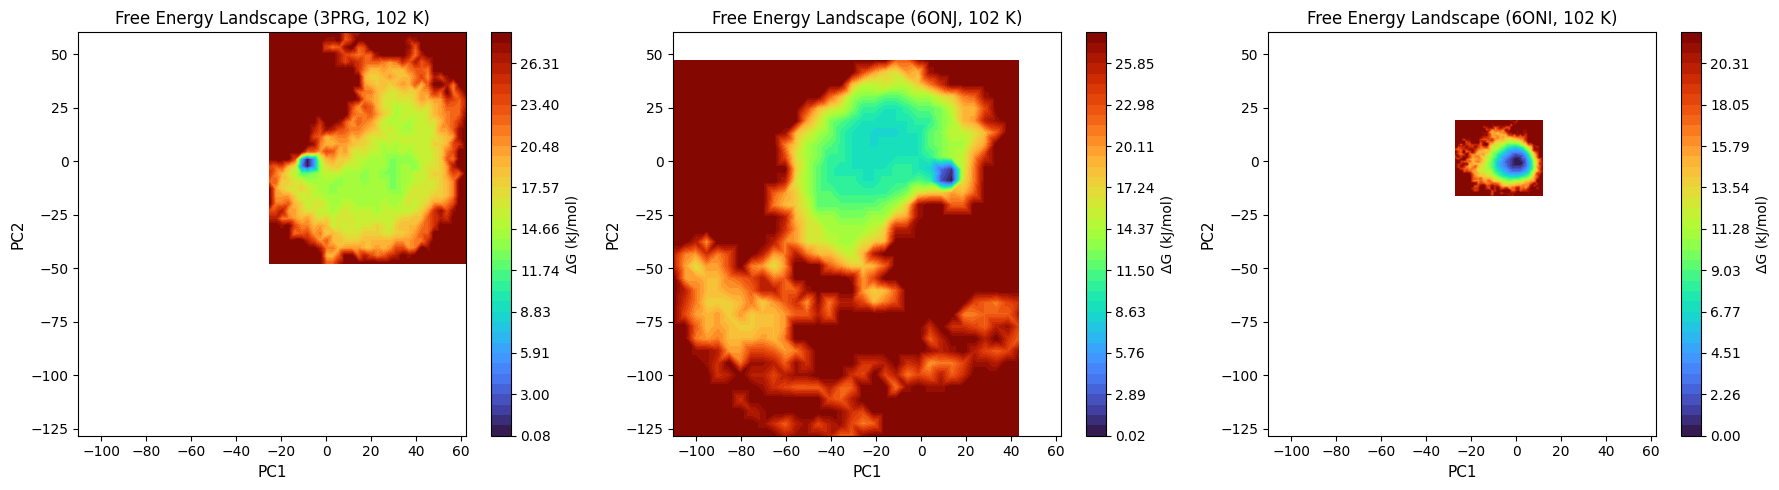

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# =========================================
# CONFIG
# =========================================
systems = ["3PRG", "6ONJ", "6ONI"]
base_path = "Advanced_Analysis"
temperature = "102"   # folder name
figsize = (18, 5)     # one row, three panels

# =========================================
# LOAD ALL DATA FIRST (to unify axes later)
# =========================================
all_data = {}

for sys in systems:
    file_path = f"{base_path}/{sys}/{temperature}/PCA/{sys}_{temperature}_gibbs.txt"
    data = np.loadtxt(file_path)

    x = data[:, 0]
    y = data[:, 1]
    z = data[:, 2]

    all_data[sys] = (x, y, z)

# compute global x/y limits for consistent panel scaling
global_xmin = min(all_data[s][0].min() for s in systems)
global_xmax = max(all_data[s][0].max() for s in systems)
global_ymin = min(all_data[s][1].min() for s in systems)
global_ymax = max(all_data[s][1].max() for s in systems)

# =========================================
# PLOTTING
# =========================================
fig, axes = plt.subplots(1, 3, figsize=figsize)

for ax, sys in zip(axes, systems):
    x, y, z = all_data[sys]

    # high-resolution grid
    xi = np.linspace(global_xmin, global_xmax, 800)
    yi = np.linspace(global_ymin, global_ymax, 800)
    X, Y = np.meshgrid(xi, yi)

    Z = griddata((x, y), z, (X, Y), method="linear")

    levels = np.linspace(np.nanmin(Z), np.nanmax(Z), 40)

    contour = ax.contourf(
        X, Y, Z,
        levels=levels,
        cmap="turbo"
    )

    ax.set_title(f"Free Energy Landscape ({sys}, {temperature} K)", fontsize=12)
    ax.set_xlabel("PC1", fontsize=11)
    ax.set_ylabel("PC2", fontsize=11)

    # individual colorbar per subplot
    cbar = fig.colorbar(contour, ax=ax)
    cbar.set_label("ΔG (kJ/mol)", fontsize=10)

    ax.grid(False)

plt.tight_layout()
plt.show()


## 📊 PCA–RMSD–Rg CSV Generation

Frame-aligned **PC1**, **PC2**, **RMSD**, and **Rg** values were extracted  
and combined into per-temperature CSV files for **3PRG**, **6ONJ**, and **6ONI**.

Each CSV is written directly into the corresponding system/temperature folder  
and serves as the unified input for downstream analysis and plotting.

Next 2 script do this for 2 folders 

In [25]:
import numpy as np
import pandas as pd
import os

systems = ["3PRG", "6ONJ", "6ONI"]
temps = [
    "100","102","104","106",
    "106.5","107","107.5","108",
    "108.5","109","109.5","110",
    "112","114","116","118"
]

BASE = "/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures"

def load_xvg_col2(fname):
    vals = []
    with open(fname) as f:
        for line in f:
            if line.startswith(("#", "@")):
                continue
            parts = line.split()
            if len(parts) >= 2:
                try:
                    vals.append(float(parts[1]))
                except:
                    pass
    return np.array(vals)

print("\n▶ Writing CSVs in SMOG_Figures")

for sys in systems:
    for T in temps:

        temp_dir = f"{BASE}/{sys}/{T}"
        if not os.path.isdir(temp_dir):
            continue

        rmsd = f"{temp_dir}/RMSD_{sys}_{T}.xvg"
        rg   = f"{temp_dir}/Rg_{sys}_{T}.xvg"
        pca  = f"{temp_dir}/{sys}_{T}_2d_proj.xvg"

        if not (os.path.isfile(rmsd) and os.path.isfile(rg) and os.path.isfile(pca)):
            continue

        RMSD = load_xvg_col2(rmsd)
        Rg   = load_xvg_col2(rg)

        proj = np.loadtxt(pca, comments=["@", "#"])
        PC1, PC2 = proj[:, 0], proj[:, 1]

        n = min(len(RMSD), len(Rg), len(PC1), len(PC2))

        df = pd.DataFrame({
            "frame": np.arange(n),
            "PC1": PC1[:n],
            "PC2": PC2[:n],
            "RMSD_nm": RMSD[:n],
            "Rg_nm": Rg[:n],
            "temperature_K": float(T),
            "system": sys
        })

        outcsv = f"{temp_dir}/{sys}_{T}_PCA_RMSD_Rg.csv"
        df.to_csv(outcsv, index=False)

        print(f"  ✅ {outcsv}")

print("🎯 SMOG_Figures CSV generation complete")



▶ Writing CSVs in SMOG_Figures
  ✅ /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/100/3PRG_100_PCA_RMSD_Rg.csv
  ✅ /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/102/3PRG_102_PCA_RMSD_Rg.csv
  ✅ /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/104/3PRG_104_PCA_RMSD_Rg.csv
  ✅ /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/106/3PRG_106_PCA_RMSD_Rg.csv
  ✅ /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/106.5/3PRG_106.5_PCA_RMSD_Rg.csv
  ✅ /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/107/3PRG_107_PCA_RMSD_Rg.csv
  ✅ /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/107.5/3PRG_107.5_PCA_RMSD_Rg.csv
  ✅ /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/108/3PRG_108_PCA_RMSD_Rg.csv
  ✅ /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures/3PRG/108.5/3P

In [32]:
import numpy as np
import pandas as pd
import os

# =========================
# CONFIG
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]

temps = [
    "100","102","104","106",
    "106.5","107","107.5","108",
    "108.5","109","109.5","110",
    "112","114","116","118"
]

ROOTS = [
    "Advanced_Analysis",
]

# =========================
# HELPERS
# =========================
def load_xvg_second_column(fname):
    """Read ONLY the 2nd numeric column from an XVG file."""
    vals = []
    with open(fname) as f:
        for line in f:
            if line.startswith(("#", "@")):
                continue
            parts = line.split()
            if len(parts) >= 2:
                try:
                    vals.append(float(parts[1]))
                except ValueError:
                    pass
    return np.array(vals)

# =========================
# MAIN LOOP
# =========================
for BASE in ROOTS:

    print(f"\n📂 Processing ROOT: {BASE}")

    for sys in systems:
        print(f"▶ System: {sys}")

        for T in temps:

            rmsd_file = f"{BASE}/{sys}/{T}/RMSD_{sys}_{T}.xvg"
            rg_file   = f"{BASE}/{sys}/{T}/Rg_{sys}_{T}.xvg"
            pca_file  = f"{BASE}/{sys}/{T}/PCA/{sys}_{T}_2d_proj.xvg"

            # All inputs must exist IN THIS ROOT
            if not (os.path.isfile(rmsd_file) and
                    os.path.isfile(rg_file) and
                    os.path.isfile(pca_file)):
                continue

            # Load data
            RMSD = load_xvg_second_column(rmsd_file)
            Rg   = load_xvg_second_column(rg_file)

            proj = np.loadtxt(pca_file, comments=["@", "#"])
            PC1, PC2 = proj[:, 0], proj[:, 1]

            # Align by frame index
            n = min(len(RMSD), len(Rg), len(PC1), len(PC2))

            # Build dataframe
            df = pd.DataFrame({
                "frame": np.arange(n),
                "PC1": PC1[:n],
                "PC2": PC2[:n],
                "RMSD_nm": RMSD[:n],
                "Rg_nm": Rg[:n],
                "temperature_K": float(T),
                "system": sys
            })

            # ✅ WRITE DIRECTLY INTO TEMP FOLDER
            outcsv = f"{BASE}/{sys}/{T}/{sys}_{T}_PCA_RMSD_Rg.csv"
            df.to_csv(outcsv, index=False)

            print(f"  ✅ Wrote: {outcsv}")

print("\n🎯 CSV generation finished (written directly into temperature folders)")



📂 Processing ROOT: Advanced_Analysis
▶ System: 3PRG
  ✅ Wrote: Advanced_Analysis/3PRG/100/3PRG_100_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/102/3PRG_102_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/104/3PRG_104_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/106/3PRG_106_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/106.5/3PRG_106.5_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/107/3PRG_107_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/107.5/3PRG_107.5_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/108/3PRG_108_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/108.5/3PRG_108.5_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/109/3PRG_109_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/109.5/3PRG_109.5_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/110/3PRG_110_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/112/3PRG_112_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/114/3PRG_114_PCA_RMSD_Rg.csv
  ✅ Wrote: Advanced_Analysis/3PRG/116/3PRG_116_PC

# ✅ SANITY CHECK — CSV FRAME CONSISTENCY

All verified CSV files passed the integrity checks successfully.

**Summary**
- All detected CSV files contain **210,001 frames**
- Required columns are present:
  - `frame`, `PC1`, `PC2`, `RMSD_nm`, `Rg_nm`
- No missing values (NaNs) detected
- Frame indices are **sequential and aligned** (0 → 210000)
- Column lengths are consistent across all observables

**Conclusion**
The datasets are **clean, synchronized, and analysis-ready** across temperatures and systems. No preprocessing corrections are required at this stage.


In [35]:
import pandas as pd
import os

# =========================
# CONFIG
# =========================
systems = ["3PRG", "6ONJ", "6ONI"]

temps = [
    "100","102","104","106",
    "106.5","107","107.5","108",
    "108.5","109","109.5","110",
    "112","114","116","118"
]

ROOTS = [
    "/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/Advanced_Analysis",
    "/panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Figures"
]

# =========================
# SANITY CHECK
# =========================
errors = 0

for BASE in ROOTS:
    print(f"\n📂 Checking ROOT: {BASE}")

    for sys in systems:
        for T in temps:

            csv_file = f"{BASE}/{sys}/{T}/{sys}_{T}_PCA_RMSD_Rg.csv"

            if not os.path.isfile(csv_file):
                continue

            df = pd.read_csv(csv_file)

            n = len(df)

            # ---- Column presence ----
            required_cols = ["frame", "PC1", "PC2", "RMSD_nm", "Rg_nm"]
            missing = [c for c in required_cols if c not in df.columns]

            if missing:
                print(f"❌ {sys} {T} K — missing columns: {missing}")
                errors += 1
                continue

            # ---- Length consistency ----
            lengths = {c: df[c].notna().sum() for c in required_cols}

            if len(set(lengths.values())) != 1:
                print(f"❌ {sys} {T} K — column length mismatch: {lengths}")
                errors += 1
                continue

            # ---- Frame index sanity ----
            if not (df["frame"].iloc[0] == 0 and df["frame"].iloc[-1] == n - 1):
                print(f"❌ {sys} {T} K — frame index not sequential")
                errors += 1
                continue

            # ---- NaN check ----
            if df[required_cols].isna().any().any():
                print(f"❌ {sys} {T} K — NaN values detected")
                errors += 1
                continue

            print(f"✅ {sys} {T} K — CSV aligned ({n} frames)")

# =========================
# FINAL STATUS
# =========================
if errors == 0:
    print("\n🎯 SANITY CHECK PASSED — all CSV files are frame-consistent")
else:
    print(f"\n⚠️ SANITY CHECK FAILED — {errors} issue(s) detected")



📂 Checking ROOT: /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish/Advanced_Analysis
✅ 3PRG 100 K — CSV aligned (210001 frames)
✅ 3PRG 102 K — CSV aligned (210001 frames)
✅ 3PRG 104 K — CSV aligned (210001 frames)
✅ 3PRG 106 K — CSV aligned (210001 frames)
✅ 3PRG 106.5 K — CSV aligned (210001 frames)
✅ 3PRG 107 K — CSV aligned (210001 frames)
✅ 3PRG 107.5 K — CSV aligned (210001 frames)
✅ 3PRG 108 K — CSV aligned (210001 frames)
✅ 3PRG 108.5 K — CSV aligned (210001 frames)
✅ 3PRG 109 K — CSV aligned (210001 frames)
✅ 3PRG 109.5 K — CSV aligned (210001 frames)
✅ 3PRG 110 K — CSV aligned (210001 frames)
✅ 3PRG 112 K — CSV aligned (210001 frames)
✅ 3PRG 114 K — CSV aligned (210001 frames)
✅ 3PRG 116 K — CSV aligned (210001 frames)
✅ 3PRG 118 K — CSV aligned (210001 frames)
✅ 6ONJ 100 K — CSV aligned (210001 frames)
✅ 6ONJ 102 K — CSV aligned (210001 frames)
✅ 6ONJ 104 K — CSV aligned (210001 frames)
✅ 6ONJ 106 K — CSV aligned (210001 frames)
✅ 6ONJ 106.5 K — 

### 📈 PCA Landscape Colored by RMSD (3PRG, 102 K)

This script visualizes the **PC1–PC2 conformational landscape** for **3PRG at 102 K**, with each point **colored continuously by RMSD (nm)**.

- **Axes:** PC1 vs PC2  
- **Color scale:** RMSD (nm), using a continuous colormap  
- **Interpretation:** Highlights how structural deviation varies across the PCA space, enabling direct identification of low- and high-RMSD regions within the sampled ensemble.


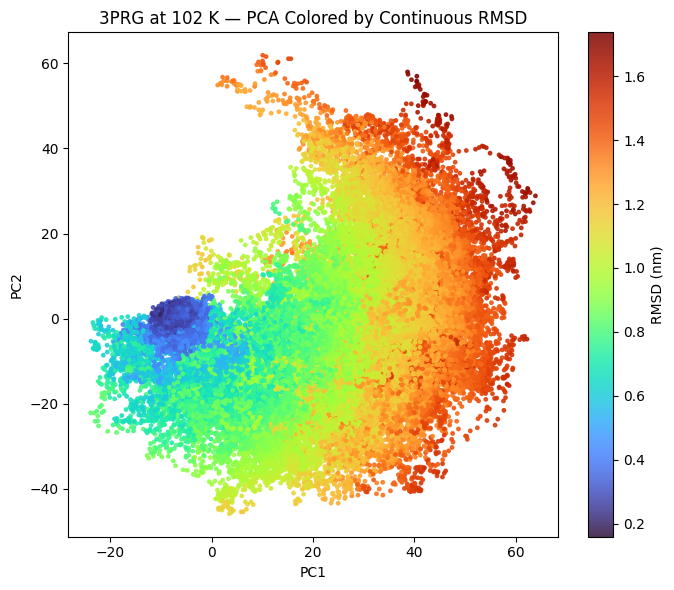

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# LOAD CSV
# =========================
df = pd.read_csv("Advanced_Analysis/3PRG/102/3PRG_102_PCA_RMSD_Rg.csv")

PC1  = df["PC1"].values
PC2  = df["PC2"].values
RMSD = df["RMSD_nm"].values

# =========================
# PLOT
# =========================
plt.figure(figsize=(7, 6))

sc = plt.scatter(
    PC1, PC2,
    c=RMSD,
    cmap="turbo",
    s=6,
    alpha=0.85
)

cbar = plt.colorbar(sc)
cbar.set_label("RMSD (nm)")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("3PRG at 102 K — PCA Colored by Continuous RMSD")

plt.grid(False)
plt.tight_layout()
plt.show()


# 🧬 3PRG — PCA Colored by RMSD with k-Means Centroids

This analysis combines **PCA projections (PC1–PC2)** with **RMSD values** derived from the SMOG simulations of **3PRG**.

A **k-means clustering (k = 3)** is performed **directly on RMSD** to identify representative conformational states.  
The resulting **cluster centers** are mapped back onto the PCA landscape to visualize how structural deviation correlates with dominant motions.

**Figure features**
- Each point represents a simulation frame in PC1–PC2 space
- Points are colored by **continuous RMSD**
- ⭐ Star marks the **initial frame**
- △ White triangles mark **RMSD cluster centroids**
- Numbers indicate cluster identity (ordered by increasing RMSD)

This provides a compact, quantitative link between **global conformational space (PCA)** and **structural deviation (RMSD)** for 3PRG.



✅ RMSD cluster centers (k=3):
Cluster 1: 0.278
Cluster 2: 0.849
Cluster 3: 1.232

✅ RMSD cluster centroids and representative frame indices (k=3):

Cluster 1: RMSD = 0.2777 nm  |  Representative frame index = 175504
Cluster 2: RMSD = 0.8494 nm  |  Representative frame index = 55329
Cluster 3: RMSD = 1.2324 nm  |  Representative frame index = 67027


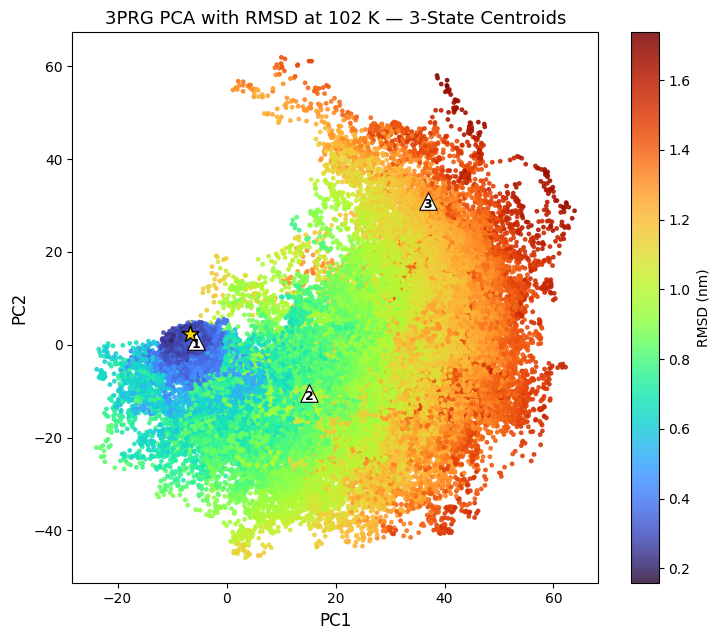


✅ PCA figure saved to:
Advanced_Analysis/3PRG/102/Plots/PCA_RMSD_k3_centroids.png


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================================
# USER SETTINGS
# ==========================================================
k = 3
csv_file = "Advanced_Analysis/3PRG/102/3PRG_102_PCA_RMSD_Rg.csv"

outdir = "Advanced_Analysis/3PRG/102/Plots"
os.makedirs(outdir, exist_ok=True)

png_out = f"{outdir}/PCA_RMSD_k{k}_centroids.png"

# ==========================================================
# LOAD CSV
# ==========================================================
df = pd.read_csv(csv_file)

PC1  = df["PC1"].values
PC2  = df["PC2"].values
RMSD = df["RMSD_nm"].values

# ==========================================================
# PURE NUMPY K-MEANS ON RMSD
# ==========================================================
RMSD_vec = RMSD.reshape(-1, 1)

def kmeans_numpy(X, k=3, n_iter=100):
    rng = np.random.default_rng(42)
    centers = X[rng.choice(len(X), k, replace=False)]

    for _ in range(n_iter):
        distances = np.abs(X - centers.T)
        labels = np.argmin(distances, axis=1)
        new_centers = np.array([X[labels == i].mean() for i in range(k)])

        if np.allclose(centers.flatten(), new_centers):
            break
        centers = new_centers.reshape(-1, 1)

    return labels, centers.flatten()

labels, centers = kmeans_numpy(RMSD_vec, k=k)
centers_sorted = np.sort(centers)

# ==========================================================
# PRINT CLUSTER SUMMARY
# ==========================================================
print(f"\n✅ RMSD cluster centers (k={k}):")
for i, c in enumerate(centers_sorted, start=1):
    print(f"Cluster {i}: {c:.3f}")

print(f"\n✅ RMSD cluster centroids and representative frame indices (k={k}):\n")
for i, c in enumerate(centers_sorted, start=1):
    idx = np.argmin(np.abs(RMSD - c))
    print(
        f"Cluster {i}: RMSD = {c:.4f} nm  |  "
        f"Representative frame index = {idx}"
    )

# ==========================================================
# PCA SCATTER COLORED BY CONTINUOUS RMSD
# ==========================================================
plt.figure(figsize=(7.5, 6.5))

sc = plt.scatter(
    PC1, PC2,
    c=RMSD,
    cmap="turbo",
    s=6,
    alpha=0.85,
    zorder=1
)

cbar = plt.colorbar(sc)
cbar.set_label("RMSD (nm)")

# Star for first frame
plt.scatter(
    PC1[0], PC2[0],
    marker="*",
    s=160,
    edgecolor="black",
    facecolor="gold",
    linewidth=1.0,
    zorder=4
)

# ==========================================================
# RMSD CENTROID MARKERS
# ==========================================================
y_offset = 0.007 * (PC2.max() - PC2.min())

for i, c in enumerate(centers_sorted, start=1):
    idx = np.argmin(np.abs(RMSD - c))
    x, y = PC1[idx], PC2[idx]

    plt.scatter(
        x, y,
        marker="^",
        s=160,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=3
    )

    plt.text(
        x, y - y_offset,
        str(i),
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        zorder=4
    )

# ==========================================================
# FINAL STYLING
# ==========================================================
plt.xlabel("PC1", fontsize=12)
plt.ylabel("PC2", fontsize=12)
plt.title(f"3PRG PCA with RMSD at 102 K — {k}-State Centroids", fontsize=13)

plt.grid(False)
plt.tight_layout()
plt.savefig(png_out, dpi=300, bbox_inches="tight")
plt.show()

print(f"\n✅ PCA figure saved to:\n{png_out}")


### 🧬 Centroid Extraction (3PRG, 102 K)

Extracts **PDB snapshots at RMSD centroid times (ps)** from the trajectory using `gmx trjconv`, generating representative structures for structural inspection.


In [58]:
%%bash

# ==============================
# ✅ USER TOGGLES (EDIT ONLY THIS)
# ==============================

TPR="3PRG/102/t-3PRG.tpr"
XTC="3PRG/102__trajout.xtc"
OUTDIR="Advanced_Analysis/3PRG/102/Plots"

# ✅ List of centroid TIMES in ps (not frames!)
CENTROID_TIMES=(175504 55329 67027)   # <-- add/remove any number here

# ==============================
# ✅ EXTRACTION LOOP (DO NOT EDIT BELOW)
# ==============================

i=1
for time_ps in "${CENTROID_TIMES[@]}"; do

    echo "▶ Extracting centroid $i | Time = ${time_ps} ps"

    gmx_mpi trjconv \
      -s "$TPR" \
      -f "$XTC" \
      -o "$OUTDIR/3PRG_102_centroid_${i}.pdb" \
      -dump "$time_ps" <<EOF
1
EOF

    ((i++))

done

echo "✅ All centroid structures extracted successfully."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

▶ Extracting centroid 1 | Time = 175504 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 3PRG/102/t-3PRG.tpr -f 3PRG/102__trajout.xtc -o Advanced_Analysis/3PRG/102/Plots/3PRG_102_centroid_1.pdb -dump 175504

Will write pdb: Protein data bank file
Reading file 3PRG/102/t-3PRG.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 3PRG/102/t-3PRG.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainC

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
▶ Extracting centroid 2 | Time = 55329 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 3PRG/102/t-3PRG.tpr -f 3PRG/102__trajout.xtc -o Advanced_Analysis/3PRG/102/Plots/3PRG_102_centroid_2.pdb -dump 55329

Will write pdb: Protein data bank file
Reading file 3PRG/102/t-3PRG.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 3PRG/102/t-3PRG.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainCh

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
▶ Extracting centroid 3 | Time = 67027 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 3PRG/102/t-3PRG.tpr -f 3PRG/102__trajout.xtc -o Advanced_Analysis/3PRG/102/Plots/3PRG_102_centroid_3.pdb -dump 67027

Will write pdb: Protein data bank file
Reading file 3PRG/102/t-3PRG.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 3PRG/102/t-3PRG.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainCh

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
✅ All centroid structures extracted successfully.


# 🧬 6ONJ — PCA Colored by RMSD with k-Means Centroids

This analysis combines **PCA projections (PC1–PC2)** with **RMSD values** derived from the SMOG simulations of **6ONJ**.

A **k-means clustering (k = 3)** is performed **directly on RMSD** to identify representative conformational states.  
The resulting **cluster centers** are mapped back onto the PCA landscape to visualize how structural deviation correlates with dominant motions.

**Figure features**
- Each point represents a simulation frame in PC1–PC2 space  
- Points are colored by **continuous RMSD**  
- ⭐ Star marks the **initial frame**  
- △ White triangles mark **RMSD cluster centroids**  
- Numbers indicate cluster identity (ordered by increasing RMSD)

This provides a compact, quantitative link between **global conformational space (PCA)** and **structural deviation (RMSD)** for **6ONJ**.



✅ RMSD cluster centers (k=3):
Cluster 1: 0.341
Cluster 2: 1.122
Cluster 3: 2.800

✅ RMSD cluster centroids and representative frame indices (k=3):

Cluster 1: RMSD = 0.3412 nm  |  Representative frame index = 2221
Cluster 2: RMSD = 1.1223 nm  |  Representative frame index = 129179
Cluster 3: RMSD = 2.7997 nm  |  Representative frame index = 209039


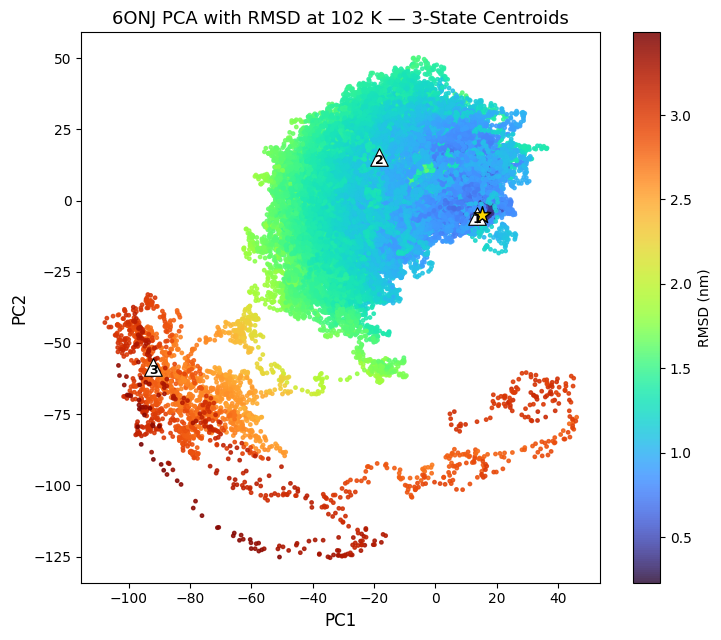


✅ PCA figure saved to:
Advanced_Analysis/6ONJ/102/Plots/PCA_RMSD_k3_centroids.png


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================================
# USER SETTINGS
# ==========================================================
k = 3
csv_file = "Advanced_Analysis/6ONJ/102/6ONJ_102_PCA_RMSD_Rg.csv"

outdir = "Advanced_Analysis/6ONJ/102/Plots"
os.makedirs(outdir, exist_ok=True)

png_out = f"{outdir}/PCA_RMSD_k{k}_centroids.png"

# ==========================================================
# LOAD CSV
# ==========================================================
df = pd.read_csv(csv_file)

PC1  = df["PC1"].values
PC2  = df["PC2"].values
RMSD = df["RMSD_nm"].values

# ==========================================================
# PURE NUMPY K-MEANS ON RMSD
# ==========================================================
RMSD_vec = RMSD.reshape(-1, 1)

def kmeans_numpy(X, k=3, n_iter=100):
    rng = np.random.default_rng(42)
    centers = X[rng.choice(len(X), k, replace=False)]

    for _ in range(n_iter):
        distances = np.abs(X - centers.T)
        labels = np.argmin(distances, axis=1)
        new_centers = np.array([X[labels == i].mean() for i in range(k)])

        if np.allclose(centers.flatten(), new_centers):
            break
        centers = new_centers.reshape(-1, 1)

    return labels, centers.flatten()

labels, centers = kmeans_numpy(RMSD_vec, k=k)
centers_sorted = np.sort(centers)

# ==========================================================
# PRINT CLUSTER SUMMARY (EXACTLY WHAT YOU WANT)
# ==========================================================
print(f"\n✅ RMSD cluster centers (k={k}):")
for i, c in enumerate(centers_sorted, start=1):
    print(f"Cluster {i}: {c:.3f}")

print(f"\n✅ RMSD cluster centroids and representative frame indices (k={k}):\n")

for i, c in enumerate(centers_sorted, start=1):
    idx = np.argmin(np.abs(RMSD - c))
    print(
        f"Cluster {i}: RMSD = {c:.4f} nm  |  "
        f"Representative frame index = {idx}"
    )

# ==========================================================
# PCA SCATTER COLORED BY CONTINUOUS RMSD
# ==========================================================
plt.figure(figsize=(7.5, 6.5))

sc = plt.scatter(
    PC1, PC2,
    c=RMSD,
    cmap="turbo",
    s=6,
    alpha=0.85,
    zorder=1
)

cbar = plt.colorbar(sc)
cbar.set_label("RMSD (nm)")

# Star for first frame
plt.scatter(
    PC1[0], PC2[0],
    marker="*",
    s=160,
    edgecolor="black",
    facecolor="gold",
    linewidth=1.0,
    zorder=4
)

# ==========================================================
# RMSD CENTROID MARKERS
# ==========================================================
y_offset = 0.007 * (PC2.max() - PC2.min())

for i, c in enumerate(centers_sorted, start=1):
    idx = np.argmin(np.abs(RMSD - c))

    x = PC1[idx]
    y = PC2[idx]

    plt.scatter(
        x, y,
        marker="^",
        s=160,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=3
    )

    plt.text(
        x, y - y_offset,
        str(i),
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        zorder=4
    )

# ==========================================================
# FINAL STYLING
# ==========================================================
plt.xlabel("PC1", fontsize=12)
plt.ylabel("PC2", fontsize=12)
plt.title(f"6ONJ PCA with RMSD at 102 K — {k}-State Centroids", fontsize=13)

plt.grid(False)
plt.tight_layout()
plt.savefig(png_out, dpi=300, bbox_inches="tight")
plt.show()

print(f"\n✅ PCA figure saved to:\n{png_out}")


### 🧬 Centroid Extraction (6ONJ, 102 K)

Extracts **PDB snapshots at RMSD centroid times (ps)** from the trajectory using `gmx trjconv`, generating representative structures for structural inspection.


In [ ]:
%%bash

# ==============================
# ✅ USER TOGGLES (EDIT ONLY THIS)
# ==============================

TPR="6ONJ/102/t-6ONJ.tpr"
XTC="6ONJ/102__trajout.xtc"
OUTDIR="Advanced_Analysis/6ONJ/102/Plots"

# ✅ List of centroid TIMES in ps (not frames!)
CENTROID_TIMES=(2221 129179 209039)   # <-- add/remove any number here

# ==============================
# ✅ EXTRACTION LOOP (DO NOT EDIT BELOW)
# ==============================

i=1
for time_ps in "${CENTROID_TIMES[@]}"; do

    echo "▶ Extracting centroid $i | Time = ${time_ps} ps"

    gmx_mpi trjconv \
      -s "$TPR" \
      -f "$XTC" \
      -o "$OUTDIR/6ONJ_102_centroid_${i}.pdb" \
      -dump "$time_ps" <<EOF
0
EOF

    ((i++))

done

echo "✅ All centroid structures extracted successfully."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

▶ Extracting centroid 1 | Time = 2221 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONJ/102/t-6ONJ.tpr -f 6ONJ/102__trajout.xtc -o Advanced_Analysis/6ONJ/102/Plots/6ONJ_102_centroid_1.pdb -dump 2221

Will write pdb: Protein data bank file
Reading file 6ONJ/102/t-6ONJ.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONJ/102/t-6ONJ.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainCha

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
▶ Extracting centroid 2 | Time = 129179 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONJ/102/t-6ONJ.tpr -f 6ONJ/102__trajout.xtc -o Advanced_Analysis/6ONJ/102/Plots/6ONJ_102_centroid_2.pdb -dump 129179

Will write pdb: Protein data bank file
Reading file 6ONJ/102/t-6ONJ.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONJ/102/t-6ONJ.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainC

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
▶ Extracting centroid 3 | Time = 209039 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONJ/102/t-6ONJ.tpr -f 6ONJ/102__trajout.xtc -o Advanced_Analysis/6ONJ/102/Plots/6ONJ_102_centroid_3.pdb -dump 209039

Will write pdb: Protein data bank file
Reading file 6ONJ/102/t-6ONJ.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONJ/102/t-6ONJ.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainC

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
✅ All centroid structures extracted successfully.


# 🧬 6ONI — PCA Colored by RMSD with k-Means Centroids

This analysis combines **PCA projections (PC1–PC2)** with **RMSD values** derived from the SMOG simulations of **6ONI**.

A **k-means clustering (k = 3)** is performed **directly on RMSD** to identify representative conformational states.  
The resulting **cluster centers** are mapped back onto the PCA landscape to visualize how structural deviation correlates with dominant motions.

**Figure features**
- Each point represents a simulation frame in PC1–PC2 space  
- Points are colored by **continuous RMSD**  
- ⭐ Star marks the **initial frame**  
- △ White triangles mark **RMSD cluster centroids**  
- Numbers indicate cluster identity (ordered by increasing RMSD)

This provides a compact, quantitative link between **global conformational space (PCA)** and **structural deviation (RMSD)** for **6ONI**.



✅ RMSD cluster centers (k=3):
Cluster 1: 0.324
Cluster 2: 0.389
Cluster 3: 0.499

✅ RMSD cluster centroids and representative frame indices (k=3):

Cluster 1: RMSD = 0.3238 nm  |  Representative frame index = 50742
Cluster 2: RMSD = 0.3894 nm  |  Representative frame index = 22328
Cluster 3: RMSD = 0.4990 nm  |  Representative frame index = 15733


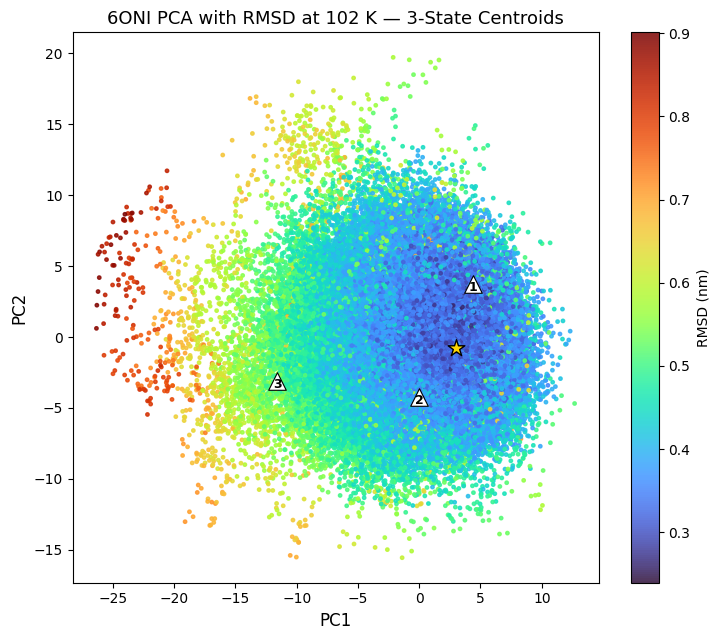


✅ PCA figure saved to:
Advanced_Analysis/6ONI/102/Plots/PCA_RMSD_k3_centroids.png


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================================
# USER SETTINGS
# ==========================================================
k = 3
csv_file = "Advanced_Analysis/6ONI/102/6ONI_102_PCA_RMSD_Rg.csv"

outdir = "Advanced_Analysis/6ONI/102/Plots"
os.makedirs(outdir, exist_ok=True)

png_out = f"{outdir}/PCA_RMSD_k{k}_centroids.png"

# ==========================================================
# LOAD CSV
# ==========================================================
df = pd.read_csv(csv_file)

PC1  = df["PC1"].values
PC2  = df["PC2"].values
RMSD = df["RMSD_nm"].values

# ==========================================================
# PURE NUMPY K-MEANS ON RMSD
# ==========================================================
RMSD_vec = RMSD.reshape(-1, 1)

def kmeans_numpy(X, k=3, n_iter=100):
    rng = np.random.default_rng(42)
    centers = X[rng.choice(len(X), k, replace=False)]

    for _ in range(n_iter):
        distances = np.abs(X - centers.T)
        labels = np.argmin(distances, axis=1)
        new_centers = np.array([X[labels == i].mean() for i in range(k)])

        if np.allclose(centers.flatten(), new_centers):
            break
        centers = new_centers.reshape(-1, 1)

    return labels, centers.flatten()

labels, centers = kmeans_numpy(RMSD_vec, k=k)
centers_sorted = np.sort(centers)

# ==========================================================
# PRINT CLUSTER SUMMARY
# ==========================================================
print(f"\n✅ RMSD cluster centers (k={k}):")
for i, c in enumerate(centers_sorted, start=1):
    print(f"Cluster {i}: {c:.3f}")

print(f"\n✅ RMSD cluster centroids and representative frame indices (k={k}):\n")
for i, c in enumerate(centers_sorted, start=1):
    idx = np.argmin(np.abs(RMSD - c))
    print(
        f"Cluster {i}: RMSD = {c:.4f} nm  |  "
        f"Representative frame index = {idx}"
    )

# ==========================================================
# PCA SCATTER COLORED BY CONTINUOUS RMSD
# ==========================================================
plt.figure(figsize=(7.5, 6.5))

sc = plt.scatter(
    PC1, PC2,
    c=RMSD,
    cmap="turbo",
    s=6,
    alpha=0.85,
    zorder=1
)

cbar = plt.colorbar(sc)
cbar.set_label("RMSD (nm)")

# Star for first frame
plt.scatter(
    PC1[0], PC2[0],
    marker="*",
    s=160,
    edgecolor="black",
    facecolor="gold",
    linewidth=1.0,
    zorder=4
)

# ==========================================================
# RMSD CENTROID MARKERS
# ==========================================================
y_offset = 0.007 * (PC2.max() - PC2.min())

for i, c in enumerate(centers_sorted, start=1):
    idx = np.argmin(np.abs(RMSD - c))
    x, y = PC1[idx], PC2[idx]

    plt.scatter(
        x, y,
        marker="^",
        s=160,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=3
    )

    plt.text(
        x, y - y_offset,
        str(i),
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        zorder=4
    )

# ==========================================================
# FINAL STYLING
# ==========================================================
plt.xlabel("PC1", fontsize=12)
plt.ylabel("PC2", fontsize=12)
plt.title(f"6ONI PCA with RMSD at 102 K — {k}-State Centroids", fontsize=13)

plt.grid(False)
plt.tight_layout()
plt.savefig(png_out, dpi=300, bbox_inches="tight")
plt.show()

print(f"\n✅ PCA figure saved to:\n{png_out}")


### 🧬 Centroid Extraction (6ONI, 102 K)

Extracts **PDB snapshots at RMSD centroid times (ps)** from the trajectory using `gmx trjconv`, generating representative structures for structural inspection.


In [ ]:
%%bash

# ==============================
# ✅ USER TOGGLES (EDIT ONLY THIS)
# ==============================

TPR="6ONI/102/t-6ONI.tpr"
XTC="6ONI/102__trajout.xtc"
OUTDIR="Advanced_Analysis/6ONI/102/Plots"

# ✅ List of centroid TIMES in ps (not frames!)
CENTROID_TIMES=(50742 22328 15733 90058)   # <-- add/remove any number here

# ==============================
# ✅ EXTRACTION LOOP (DO NOT EDIT BELOW)
# ==============================

i=1
for time_ps in "${CENTROID_TIMES[@]}"; do

    echo "▶ Extracting centroid $i | Time = ${time_ps} ps"

    gmx_mpi trjconv \
      -s "$TPR" \
      -f "$XTC" \
      -o "$OUTDIR/6ONI_102_centroid_${i}.pdb" \
      -dump "$time_ps" <<EOF
0
EOF

    ((i++))

done

echo "✅ All centroid structures extracted successfully."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

▶ Extracting centroid 1 | Time = 50742 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONI/102/t-6ONI.tpr -f 6ONI/102__trajout.xtc -o Advanced_Analysis/6ONI/102/Plots/6ONI_102_centroid_1.pdb -dump 50742

Will write pdb: Protein data bank file
Reading file 6ONI/102/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONI/102/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainCh

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
▶ Extracting centroid 2 | Time = 22328 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONI/102/t-6ONI.tpr -f 6ONI/102__trajout.xtc -o Advanced_Analysis/6ONI/102/Plots/6ONI_102_centroid_2.pdb -dump 22328

Will write pdb: Protein data bank file
Reading file 6ONI/102/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONI/102/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainCh

...

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
▶ Extracting centroid 5 | Time = 135528 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONI/102/t-6ONI.tpr -f 6ONI/102__trajout.xtc -o Advanced_Analysis/6ONI/102/Plots/6ONI_102_centroid_5.pdb -dump 135528

Will write pdb: Protein data bank file
Reading file 6ONI/102/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONI/102/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainC

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
▶ Extracting centroid 6 | Time = 90058 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONI/102/t-6ONI.tpr -f 6ONI/102__trajout.xtc -o Advanced_Analysis/6ONI/102/Plots/6ONI_102_centroid_6.pdb -dump 90058

Will write pdb: Protein data bank file
Reading file 6ONI/102/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONI/102/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainCh

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
✅ All centroid structures extracted successfully.


### 🧬 6ONI — Temperature-Dependent RMSD Exchange Behavior (SEE FIGURE OUTPUT FROM THIS CELL)

For **6ONI**, no clear exchange into the **~1.5 nm RMSD intermediate** was observed at lower temperatures.  
We therefore examined the **RMSD time series across all 6ONI temperatures** and identified **109 K** as a condition where **transient exchange into the intermediate state occurs**, followed by **return to the native ensemble**.

For reference and comparison, **3PRG** and **6ONJ** RMSD traces at **109 K** are shown alongside 6ONI, highlighting the distinct temperature-dependent sampling behavior of 6ONI relative to the other systems.


# 6ONI 109K shows a blip to intermediate, and this is where we converge all conformations 

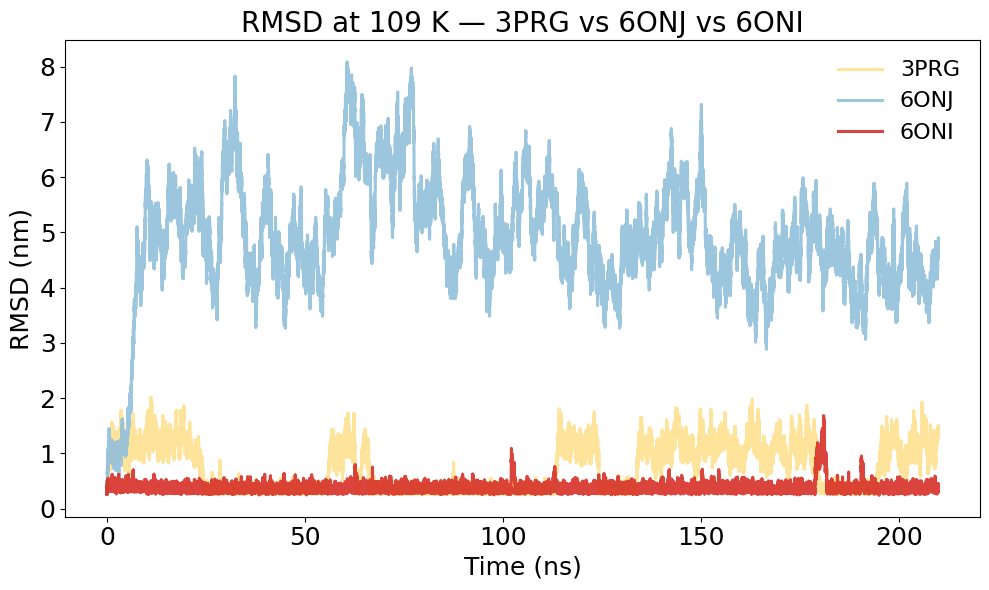

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import os

# =========================
# CONFIG
# =========================
T = "109"
systems = ["3PRG", "6ONJ", "6ONI"]
colors = {
    "6ONI": "#d73027",   # red
    "3PRG": "#fee090",   # light yellow
    "6ONJ": "#91bfdb",   # soft blue
}

BASE = "Advanced_Analysis"

plt.figure(figsize=(10, 6))

# =========================
# LOAD + PLOT EACH SYSTEM
# =========================
for sys in systems:
    fname = f"{BASE}/{sys}/{T}/RMSD_{sys}_{T}.xvg"

    if os.path.isfile(fname):
        data = np.loadtxt(fname, comments=["@", "#"])
        time = data[:, 0] / 1000.0    # convert ps → ns
        rmsd = data[:, 1]

        plt.plot(time, rmsd,
                 lw=2.2,
                 alpha=0.9,
                 color=colors[sys],
                 label=sys)

# =========================
# LABELS / TITLE / LEGEND
# =========================
plt.xlabel("Time (ns)", fontsize=18)
plt.ylabel("RMSD (nm)", fontsize=18)
plt.title("RMSD at 109 K — 3PRG vs 6ONJ vs 6ONI", fontsize=20)

plt.legend(frameon=False, fontsize=16)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

plt.grid(False)
plt.tight_layout()
plt.show()


# 🧬 6ONI — PCA Colored by RMSD with k-Means Centroids (109 K)

This analysis combines **PCA projections (PC1–PC2)** with **RMSD values** from **6ONI** SMOG simulations at **109 K**, a temperature where **transient exchange into an intermediate state** is observed.

A **k-means clustering (k = 4)** is performed **directly on RMSD** to capture native, intermediate, and higher-RMSD conformational populations.  
The resulting **RMSD cluster centers** are mapped back onto the PCA landscape to visualize how structural deviation relates to dominant collective motions.

**Figure features**
- Each point represents a simulation frame in PC1–PC2 space  
- Points are colored by **continuous RMSD**  
- ⭐ Star marks the **initial (native) frame**  
- △ White triangles mark **RMSD cluster centroids**  
- Numbers indicate cluster identity (ordered by increasing RMSD)

This figure highlights **temperature-enabled exchange behavior in 6ONI**, providing a clear link between **PCA-defined conformational space** and **RMSD-defined structural states** at 109 K.



✅ RMSD cluster centers (k=4):
Cluster 1: 0.335
Cluster 2: 0.423
Cluster 3: 0.772
Cluster 4: 1.222

✅ RMSD cluster centroids and representative frame indices (k=4):

Cluster 1: RMSD = 0.3354 nm  |  Representative frame index = 17341
Cluster 2: RMSD = 0.4230 nm  |  Representative frame index = 113516
Cluster 3: RMSD = 0.7722 nm  |  Representative frame index = 179052
Cluster 4: RMSD = 1.2222 nm  |  Representative frame index = 180861


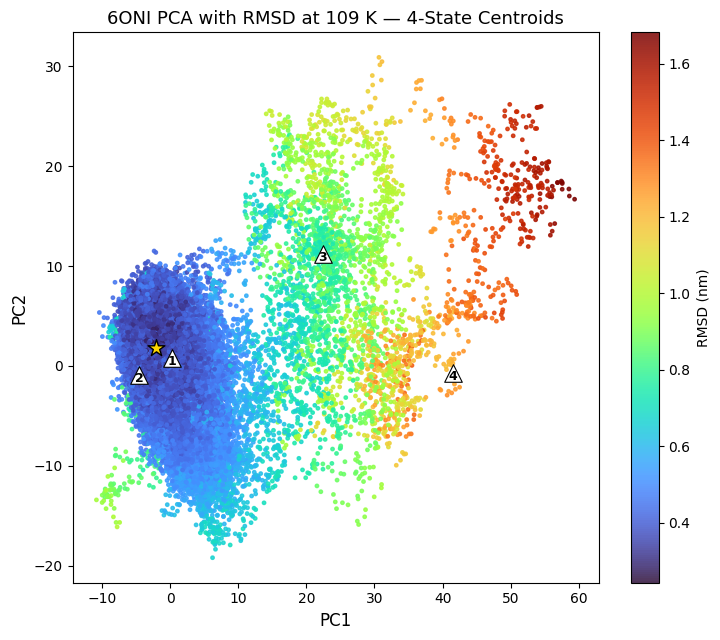


✅ PCA figure saved to:
Advanced_Analysis/6ONI/109/Plots/PCA_RMSD_k4_centroids.png


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================================
# USER SETTINGS
# ==========================================================
k = 4
csv_file = "Advanced_Analysis/6ONI/109/6ONI_109_PCA_RMSD_Rg.csv"

outdir = "Advanced_Analysis/6ONI/109/Plots"
os.makedirs(outdir, exist_ok=True)

png_out = f"{outdir}/PCA_RMSD_k{k}_centroids.png"

# ==========================================================
# LOAD CSV
# ==========================================================
df = pd.read_csv(csv_file)

PC1  = df["PC1"].values
PC2  = df["PC2"].values
RMSD = df["RMSD_nm"].values

# ==========================================================
# PURE NUMPY K-MEANS ON RMSD
# ==========================================================
RMSD_vec = RMSD.reshape(-1, 1)

def kmeans_numpy(X, k=4, n_iter=100):
    rng = np.random.default_rng(42)
    centers = X[rng.choice(len(X), k, replace=False)]

    for _ in range(n_iter):
        distances = np.abs(X - centers.T)
        labels = np.argmin(distances, axis=1)
        new_centers = np.array([X[labels == i].mean() for i in range(k)])

        if np.allclose(centers.flatten(), new_centers):
            break
        centers = new_centers.reshape(-1, 1)

    return labels, centers.flatten()

labels, centers = kmeans_numpy(RMSD_vec, k=k)
centers_sorted = np.sort(centers)

# ==========================================================
# PRINT CLUSTER SUMMARY
# ==========================================================
print(f"\n✅ RMSD cluster centers (k={k}):")
for i, c in enumerate(centers_sorted, start=1):
    print(f"Cluster {i}: {c:.3f}")

print(f"\n✅ RMSD cluster centroids and representative frame indices (k={k}):\n")
for i, c in enumerate(centers_sorted, start=1):
    idx = np.argmin(np.abs(RMSD - c))
    print(
        f"Cluster {i}: RMSD = {c:.4f} nm  |  "
        f"Representative frame index = {idx}"
    )

# ==========================================================
# PCA SCATTER COLORED BY CONTINUOUS RMSD
# ==========================================================
plt.figure(figsize=(7.5, 6.5))

sc = plt.scatter(
    PC1, PC2,
    c=RMSD,
    cmap="turbo",
    s=6,
    alpha=0.85,
    zorder=1
)

cbar = plt.colorbar(sc)
cbar.set_label("RMSD (nm)")

# Star for first frame
plt.scatter(
    PC1[0], PC2[0],
    marker="*",
    s=160,
    edgecolor="black",
    facecolor="gold",
    linewidth=1.0,
    zorder=4
)

# ==========================================================
# RMSD CENTROID MARKERS
# ==========================================================
y_offset = 0.007 * (PC2.max() - PC2.min())

for i, c in enumerate(centers_sorted, start=1):
    idx = np.argmin(np.abs(RMSD - c))
    x, y = PC1[idx], PC2[idx]

    plt.scatter(
        x, y,
        marker="^",
        s=160,
        facecolor="white",
        edgecolor="black",
        linewidth=0.8,
        zorder=3
    )

    plt.text(
        x, y - y_offset,
        str(i),
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        color="black",
        zorder=4
    )

# ==========================================================
# FINAL STYLING
# ==========================================================
plt.xlabel("PC1", fontsize=12)
plt.ylabel("PC2", fontsize=12)
plt.title(
    f"6ONI PCA with RMSD at 109 K — {k}-State Centroids",
    fontsize=13
)

plt.grid(False)
plt.tight_layout()
plt.savefig(png_out, dpi=300, bbox_inches="tight")
plt.show()

print(f"\n✅ PCA figure saved to:\n{png_out}")


### 🧬 Centroid Extraction (6ONI, 109 K)

Extracts **PDB snapshots at RMSD centroid times (ps)** from the trajectory using `gmx trjconv`, generating representative structures for structural inspection.


In [ ]:
%%bash

# ==============================
# ✅ USER TOGGLES (EDIT ONLY THIS)
# ==============================

TPR="6ONI/109/t-6ONI.tpr"
XTC="6ONI/109__trajout.xtc"
OUTDIR="Advanced_Analysis/6ONI/109/Plots"

# ✅ List of centroid TIMES in ps (not frames!)
CENTROID_TIMES=(17341 113516 179052 180861)   # <-- add/remove any number here

# ==============================
# ✅ EXTRACTION LOOP (DO NOT EDIT BELOW)
# ==============================

i=1
for time_ps in "${CENTROID_TIMES[@]}"; do

    echo "▶ Extracting centroid $i | Time = ${time_ps} ps"

    gmx_mpi trjconv \
      -s "$TPR" \
      -f "$XTC" \
      -o "$OUTDIR/6ONI_109_centroid_${i}.pdb" \
      -dump "$time_ps" <<EOF
0
EOF

    ((i++))

done

echo "✅ All centroid structures extracted successfully."


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

▶ Extracting centroid 1 | Time = 17341 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONI/109/t-6ONI.tpr -f 6ONI/109__trajout.xtc -o Advanced_Analysis/6ONI/109/Plots/6ONI_109_centroid_1.pdb -dump 17341

Will write pdb: Protein data bank file
Reading file 6ONI/109/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONI/109/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainCh

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
▶ Extracting centroid 2 | Time = 113516 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONI/109/t-6ONI.tpr -f 6ONI/109__trajout.xtc -o Advanced_Analysis/6ONI/109/Plots/6ONI_109_centroid_2.pdb -dump 113516

Will write pdb: Protein data bank file
Reading file 6ONI/109/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONI/109/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainC

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
▶ Extracting centroid 3 | Time = 179052 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONI/109/t-6ONI.tpr -f 6ONI/109__trajout.xtc -o Advanced_Analysis/6ONI/109/Plots/6ONI_109_centroid_3.pdb -dump 179052

Will write pdb: Protein data bank file
Reading file 6ONI/109/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONI/109/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainC

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
▶ Extracting centroid 4 | Time = 180861 ps


               :-) GROMACS - gmx trjconv, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/Mithun/SMOG_Sims/SMOG_Replica_Publish
Command line:
  gmx_mpi trjconv -s 6ONI/109/t-6ONI.tpr -f 6ONI/109__trajout.xtc -o Advanced_Analysis/6ONI/109/Plots/6ONI_109_centroid_4.pdb -dump 180861

Will write pdb: Protein data bank file
Reading file 6ONI/109/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file 6ONI/109/t-6ONI.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has  2178 elements
Group     1 (        Protein) has  2165 elements
Group     2 (      Protein-H) has  2165 elements
Group     3 (        C-alpha) has   270 elements
Group     4 (       Backbone) has   810 elements
Group     5 (      MainChain) has  1080 elements
Group     6 (   MainChain+Cb) has  1339 elements
Group     7 (    MainC

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 0: 'System'
✅ All centroid structures extracted successfully.
